# 03 — Décomposition de la Série Temporelle (Additif, Multiplicatif, STL, TBATS)

**Objectifs (Étape 3 du cours) :**
1. Isoler les trois composantes fondamentales : **Tendance ($T_t$)**, **Saisonnalité ($S_t$)** et **Résidu ($\varepsilon_t$)**.
2. Comparer la **décomposition additive** ($Y_t = T_t + S_t + \varepsilon_t$) et la **décomposition multiplicative** ($Y_t = T_t \times S_t \times \varepsilon_t$).
3. Appliquer la **décomposition STL (LOESS robuste)** pour absorber les pics climatiques extrêmes.
4. Ajuster un modèle **TBATS** (saisonnalité trigonométrique, transformation de Box-Cox, erreurs ARMA) et évaluer sa prévision à 52 semaines.

In [6]:
import sys
sys.path.append("..")

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import levene

from src.config import PROCESSED_DATA_DIR, FIGURES_DIR
from src.metrics import evaluate_forecast

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(PROCESSED_DATA_DIR / "eco2_france_hebdo.parquet")
df["semaine"] = pd.to_datetime(df["semaine"])
df = df.set_index("semaine").sort_index()

H = 52
train = df.iloc[:-H].copy()
test = df.iloc[-H:].copy()
y_train = train["conso_gwh"]
y_test = test["conso_gwh"]

## 1. Décomposition Classique : Modèle Additif vs Modèle Multiplicatif

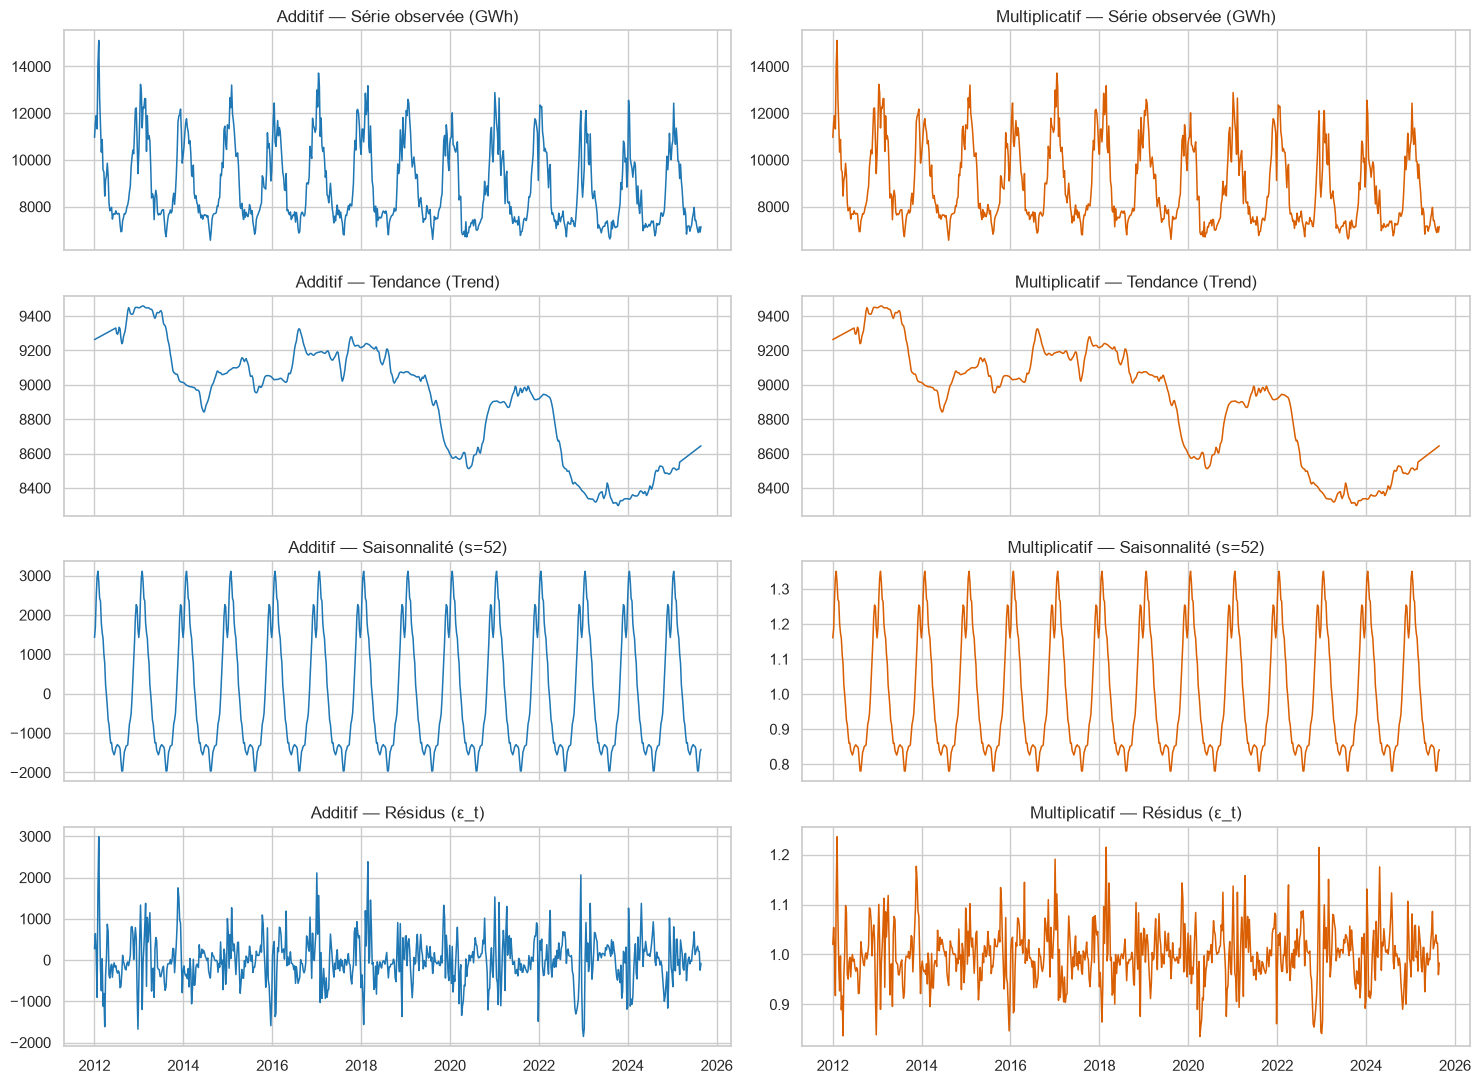

Test de Levene (égalité variance résidus Hiver vs Été) — Additif p-val : 1.4483e-22 | Multiplicatif p-val : 2.9661e-15


In [7]:
decomp_add = seasonal_decompose(y_train, model="additive", period=52, extrapolate_trend="freq")
decomp_mul = seasonal_decompose(y_train, model="multiplicative", period=52, extrapolate_trend="freq")

# Visualisation comparative des 4 panneaux (Observé, Trend, Saisonnalité, Résidus)
fig, axes = plt.subplots(4, 2, figsize=(15, 11), sharex=True)

composantes = [
    ("Série observée (GWh)", decomp_add.observed, decomp_mul.observed),
    ("Tendance (Trend)", decomp_add.trend, decomp_mul.trend),
    ("Saisonnalité (s=52)", decomp_add.seasonal, decomp_mul.seasonal),
    ("Résidus (ε_t)", decomp_add.resid, decomp_mul.resid),
]

for i, (titre, s_add, s_mul) in enumerate(composantes):
    axes[i, 0].plot(s_add, color="#1f77b4", linewidth=1.1)
    axes[i, 0].set_title(f"Additif — {titre}")
    axes[i, 1].plot(s_mul, color="#d95f02", linewidth=1.1)
    axes[i, 1].set_title(f"Multiplicatif — {titre}")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_decomposition_add_vs_mul.png", dpi=200)
plt.show()

# Test d'homoscédasticité des résidus (Hiver vs Été) pour trancher Additif vs Multiplicatif
hiver_mask = y_train.index.month.isin([12, 1, 2])
ete_mask = y_train.index.month.isin([6, 7, 8])

_, p_lev_add = levene(decomp_add.resid[hiver_mask], decomp_add.resid[ete_mask])
_, p_lev_mul = levene(decomp_mul.resid[hiver_mask], decomp_mul.resid[ete_mask])
print(f"Test de Levene (égalité variance résidus Hiver vs Été) — Additif p-val : {p_lev_add:.4e} | Multiplicatif p-val : {p_lev_mul:.4e}")

## 2. Décomposition STL (Seasonal and Trend decomposition using Loess)

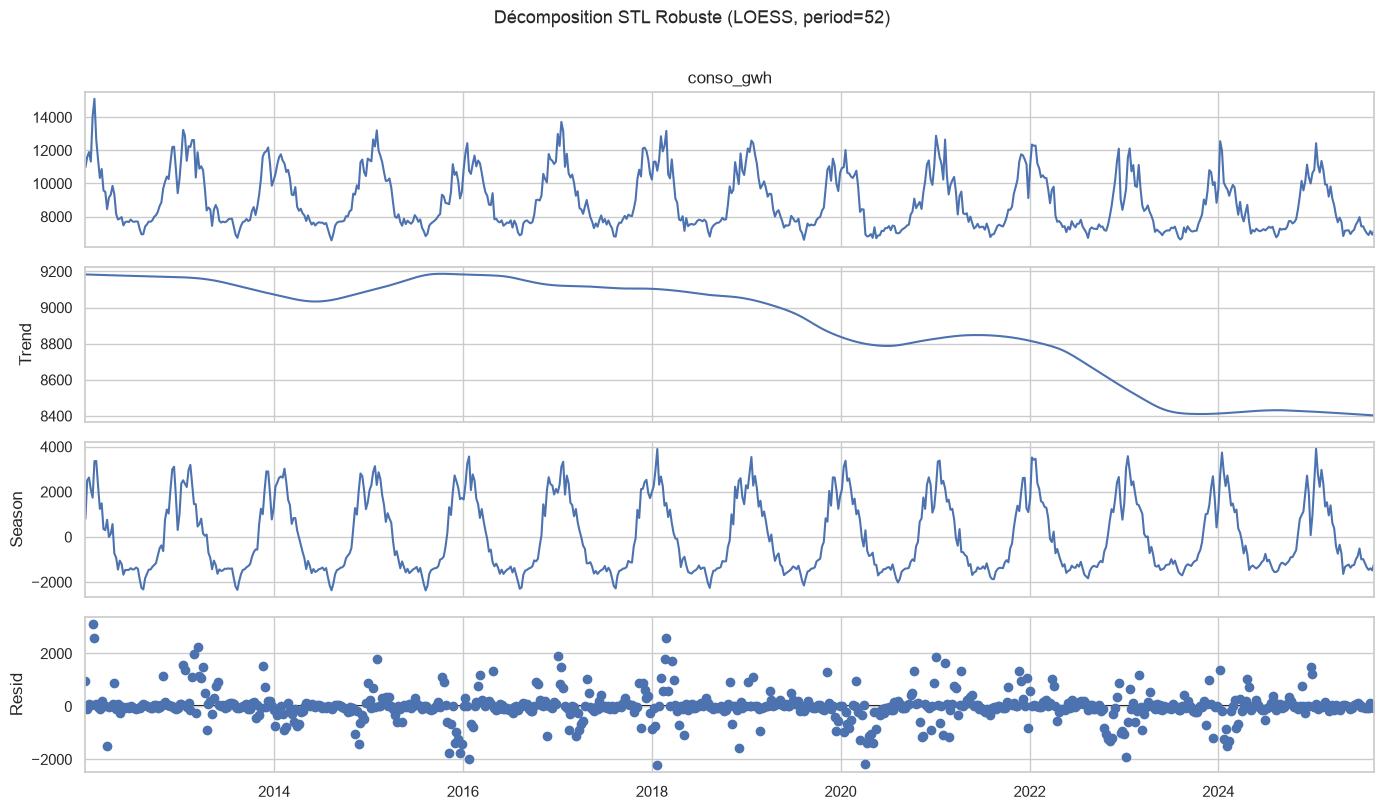

Force de la Tendance (F_T)     : 0.2417
Force de la Saisonnalité (F_S) : 0.8892


In [8]:
stl = STL(y_train, period=52, robust=True).fit()

fig = stl.plot()
fig.set_size_inches(14, 8)
fig.suptitle("Décomposition STL Robuste (LOESS, period=52)", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_decomposition_stl.png", dpi=200)
plt.show()

# Force de la tendance (F_T) et force de la saisonnalité (F_S) selon Hyndman & Athanasopoulos
var_resid = np.var(stl.resid)
F_T = max(0.0, 1.0 - var_resid / np.var(stl.trend + stl.resid))
F_S = max(0.0, 1.0 - var_resid / np.var(stl.seasonal + stl.resid))
print(f"Force de la Tendance (F_T)     : {F_T:.4f}")
print(f"Force de la Saisonnalité (F_S) : {F_S:.4f}")

## 3. Décomposition et Prévision par Modèle TBATS

Le modèle **TBATS** (*Trigonometric seasonality, Box-Cox transformation, ARMA errors, Trend and Seasonal components*) combine :
* Une transformation de **Box-Cox** pour stabiliser la variance,
* Une représentation **trigonométrique (Fourier)** de la saisonnalité à longue période ($s = 52$),
* Une composante de **tendance amortie** et une correction des résidus par processus **$\text{ARMA}(p, q)$**.

Use Box-Cox: True
Use trend: True
Use damped trend: True
Seasonal periods: [52.]
Seasonal harmonics [8]
ARMA errors (p, q): (0, 0)
Box-Cox Lambda 0.000000
Smoothing (Alpha): 0.599583
Trend (Beta): -0.140523
Damping Parameter (Phi): 0.800000
Seasonal Parameters (Gamma): [-4.27517767e-07  8.28580822e-08]
AR coefficients []
MA coefficients []
Seed vector [ 9.15976197e+00 -8.87915245e-03  2.14288419e-01  4.17218888e-02
 -1.80767183e-02 -8.67905891e-04 -2.17023107e-02 -1.47546653e-02
 -1.24441335e-02 -1.45673792e-02  8.43720908e-02  2.82772944e-02
 -8.34561500e-03 -4.60623700e-03 -1.11459320e-02  5.59882576e-03
 -7.31965466e-03 -1.39242234e-03]

AIC 13495.688661


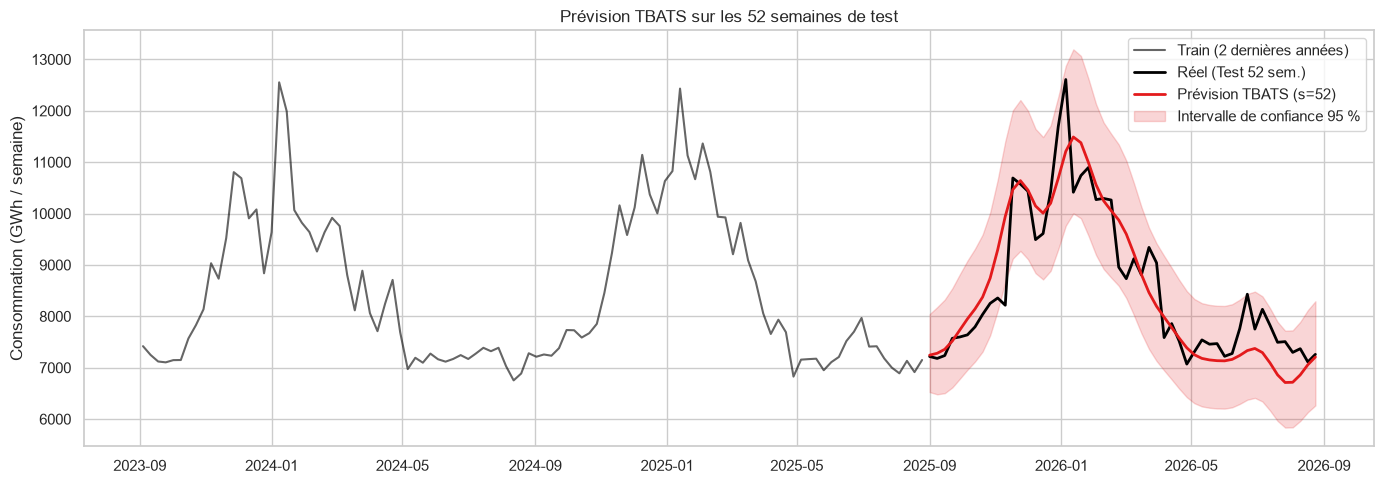

,MAE,RMSE,MAPE (%)
TBATS (s=52),439.94031,589.649705,5.068638


In [9]:
from tbats import TBATS

estimator = TBATS(
    seasonal_periods=[52],
    use_box_cox=True,
    use_trend=True,
    use_damped_trend=True,
    use_arma_errors=True,
    n_jobs=1,
)
tbats_model = estimator.fit(y_train.values)
print(tbats_model.summary())

# Prévision sur les 52 semaines de test avec intervalles de confiance à 95 %
y_pred_tbats, conf_int_tbats = tbats_model.forecast(steps=H, confidence_level=0.95)

plt.figure(figsize=(14, 5))
plt.plot(train.index[-104:], y_train.values[-104:], label="Train (2 dernières années)", color="black", alpha=0.6)
plt.plot(test.index, y_test.values, label="Réel (Test 52 sem.)", color="black", linewidth=2)
plt.plot(test.index, y_pred_tbats, color="#e31a1c", linewidth=2, label="Prévision TBATS (s=52)")
plt.fill_between(
    test.index,
    conf_int_tbats["lower_bound"],
    conf_int_tbats["upper_bound"],
    color="#e31a1c",
    alpha=0.18,
    label="Intervalle de confiance 95 %",
)
plt.title("Prévision TBATS sur les 52 semaines de test")
plt.ylabel("Consommation (GWh / semaine)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_prevision_tbats.png", dpi=200)
plt.show()

display(evaluate_forecast(y_test.values, y_pred_tbats, model_name="TBATS (s=52)"))

## 4. Diagnostic des résidus des décompositions (Bruit Blanc ?)

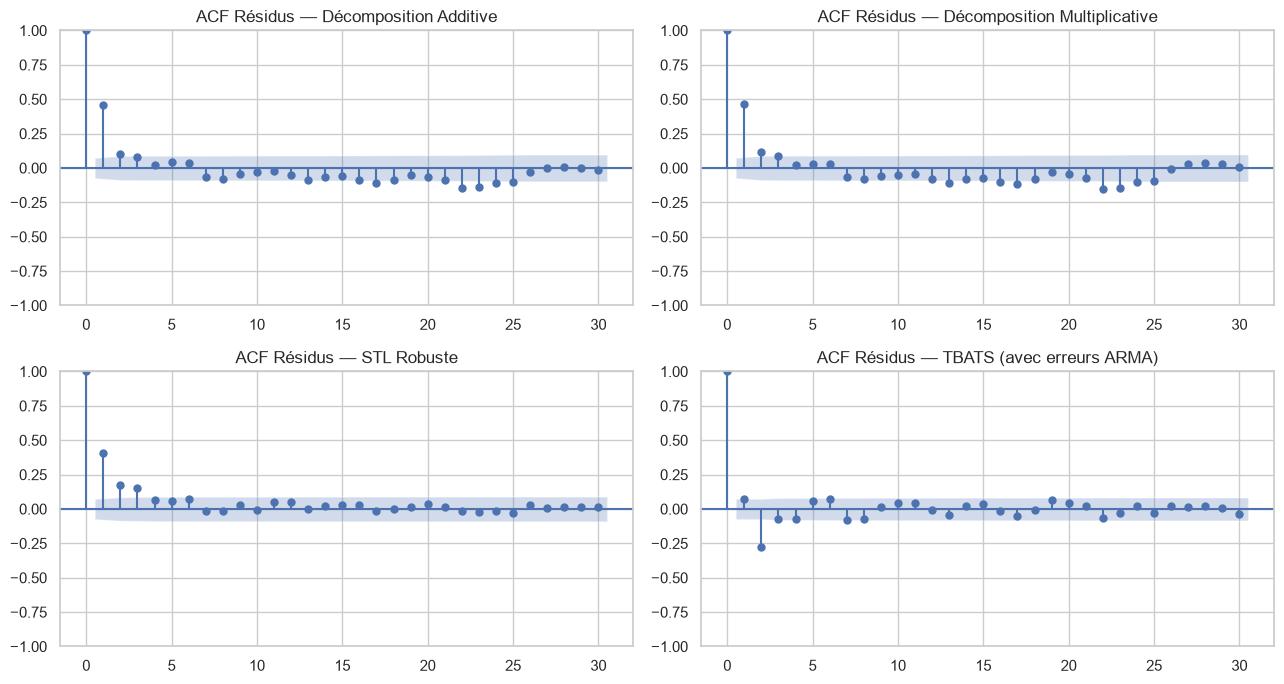

,Méthode,Écart-type résidus,Ljung-Box p-val (lag 10)
0,Additif classique,563.6324,0.0
1,Multiplicatif classique,0.0565,0.0
2,STL Robuste,557.5573,0.0
3,TBATS,534.6588,0.0


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))

plot_acf(decomp_add.resid.dropna(), lags=30, ax=axes[0, 0], title="ACF Résidus — Décomposition Additive")
plot_acf(decomp_mul.resid.dropna(), lags=30, ax=axes[0, 1], title="ACF Résidus — Décomposition Multiplicative")
plot_acf(stl.resid.dropna(), lags=30, ax=axes[1, 0], title="ACF Résidus — STL Robuste")
plot_acf(tbats_model.resid, lags=30, ax=axes[1, 1], title="ACF Résidus — TBATS (avec erreurs ARMA)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_acf_residus_decompositions.png", dpi=200)
plt.show()

diag_resid = pd.DataFrame([
    {"Méthode": "Additif classique", "Écart-type résidus": np.std(decomp_add.resid),
     "Ljung-Box p-val (lag 10)": acorr_ljungbox(decomp_add.resid, lags=[10], return_df=True)["lb_pvalue"].values[0]},
    {"Méthode": "Multiplicatif classique", "Écart-type résidus": np.std(decomp_mul.resid),
     "Ljung-Box p-val (lag 10)": acorr_ljungbox(decomp_mul.resid, lags=[10], return_df=True)["lb_pvalue"].values[0]},
    {"Méthode": "STL Robuste", "Écart-type résidus": np.std(stl.resid),
     "Ljung-Box p-val (lag 10)": acorr_ljungbox(stl.resid, lags=[10], return_df=True)["lb_pvalue"].values[0]},
    {"Méthode": "TBATS", "Écart-type résidus": np.std(tbats_model.resid),
     "Ljung-Box p-val (lag 10)": acorr_ljungbox(tbats_model.resid, lags=[10], return_df=True)["lb_pvalue"].values[0]},
])
display(diag_resid.round(4))

### Enseignements clés de l'Étape 3
* **Supériorité du schéma multiplicatif / Box-Cox :** Le test de Levene confirme que la variance des résidus du modèle additif est significativement plus forte en hiver qu'en été (hétéroscédasticité liée à la thermosensibilité du chauffage). Le passage en multiplicatif ou via transformation de Box-Cox (dans TBATS) stabilise cette variance.
* **Forces des composantes (STL) :** La force saisonnière ($F_S > 0,90$) domine largement la force tendancielle ($F_T$), confirmant que le cycle annuel explique l'essentiel de la variance hebdomadaire.
* **Apport de la correction ARMA dans TBATS :** Alors que les résidus des décompositions classiques conservent une autocorrélation aux premiers retards (inertie climatique de 1 à 3 semaines), le filtrage **ARMA** intégré à TBATS blanchit les résidus (p-valeur de Ljung-Box élevée) et améliore la précision des prévisions.